In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd

import os
import glob

from sklearn.decomposition import PCA
from prepSpec import *


*** INSERT

In [2]:
pro_path = os.path.dirname(os.getcwd())
data_path = pro_path + '\\2026-WS-PCIV'

filenames = glob.glob(data_path + '/**/*.txt', recursive=True)

In [3]:
spec_all = []
for f in filenames:
    data = pd.read_table(f, sep=' ', header=None).values
    spec_all.append(data[:, 1])

wn = data[:, 0]
spec_all = np.vstack(spec_all)

In [4]:
ix_sel = ~np.isnan(spec_all[0, :])
wn = wn[ix_sel]
spec_all = spec_all[:, ix_sel]

In [5]:
wn_new = np.array(range(301, 2425), dtype=float)
wn_new, spec_pre = do_interpolation(spec_all, wn, wn_new) 

*** INSERT

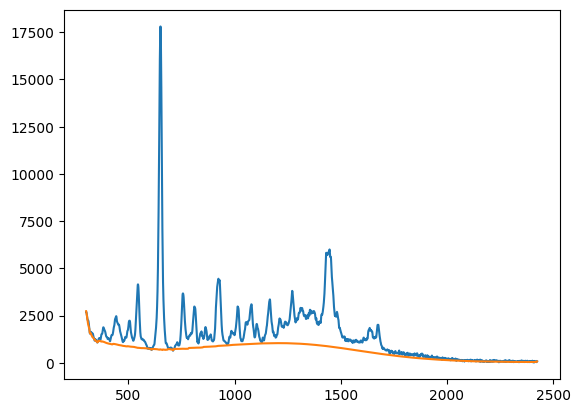

In [6]:
spec_bs = snip(spec_pre, iterations=70, return_baseline=True)
plt.plot(wn_new, spec_pre[100, :])
plt.plot(wn_new, spec_bs[100, :])
plt.show()

In [7]:
spec_pre = snip(spec_pre, iterations=70, return_baseline=False)
spec_pre = norm_spectra(spec_pre, norm_method='vector')

*** INSERT

In [8]:
groups = np.array([f.split('\\')[-3] for f in filenames])
samples = np.array([os.path.basename(f).split('-')[0] for f in filenames])

In [9]:
sample_name_pool = {
                      "0": ['Conc_00', '0'],
                      "5": ['Conc_05', '1'], 
                      "10": ['Conc_10', '2'], 
                      "15": ['Conc_15', '3'],
                      "20": ['Conc_20', '4'], 
                      "25": ['Conc_25', '5'],
                      "30": ['Conc_30', '6'],
                      "35": ['Conc_35', '7'], 
                      "40": ['Conc_40', '8'], 
                      "45": ['Conc_45', '9'],
                      "50": ['Conc_50', '10'], 
                      "55": ['Conc_55', '11'],
                      "60": ['Conc_60', '12'],
                      "Ani": ['ani', 'Ani', 'Anisöl'],
                      "Bas": ['bas', 'Bas', 'Basilikumöl'], 
                      "Est" : ['est', 'Est', 'Estragonöl'], 
                      "Fen": ['fen', 'Fen', 'Fenchelöl'],
                      "Caj": ['caj', 'Caj', 'Cajeputöl'], 
                      "Euc": ['euc', 'Euc', 'Eukalyptusöl'], 
                      "Nia": ['nia', 'Nia', 'Niaouliöl'], 
                      "Ros": ['ros', 'Ros', 'Rosmarinöl'],  
                      "OR2": ['or2', 'OR2', 'Or2', 'Orangenöl'],
                      "Gra": ['gra', 'Gra', 'Grapefruitöl'], 
                      "Tan": ['tan', 'Tan', 'Tangerinenöl'], 
                      "Zi2": ['zi2', 'Zi2', 'Zitronenöl'],
                      "Bcar": ['bcar', 'ßcar', 'Bcar', 'Beta', 'Car'], 
                      "Sqa": ['sqa', 'Sqa'],
                      "Sqe": ['sqe', 'Sqe'], 
                      "Squalen": ['Squalan', 'Squalen'],
                      "Hex": ['hex', 'Hex', 'Hexan'],
                      "4aap": ['4aap', 'para', 'paracetamol' ],
                      "poly": ['poly', 'Poly', ]
                   }

sample_type_pool = {
                      "0": ['0'],
                      "5": ['5'], 
                      "10": ['10'], 
                      "15": ['15'],
                      "20": ['20'], 
                      "25": ['25'],
                      "30": ['30'],
                      "35": ['35'], 
                      "40": ['40'], 
                      "45": ['45'],
                      "50": ['50'], 
                      "55": ['55'],
                      "60": ['60'],
                      "Pheny": ['Ani', 'Bas', 'Est', 'Fen'],
                      "Eukaly": ['Caj', 'Euc', 'Nia', 'Ros'],  
                      "Zitrus": ['OR2', 'Gra', 'Tan', 'Zi2'],
                      "Other": ['Bcar', 'Sqa', 'Sqe', 'Squalen', 'Hex'],
                      "4aap": ['4aap'],
                      "poly": ['poly']
                   }

sample_task_pool = {
                      "calibration": [str(i) for i in range(0, 65, 5)],
                      "classification": ["Pheny", "Eukaly", "Zitrus"], 
                      "standard": ["4aap", "poly"], 
                      "other": ["Other"],
                    }

def get_name(name, pool):
    for p in pool.keys():
        if name in pool[p]:
            return p
    return name

In [10]:
samples = np.array([get_name(n, sample_name_pool) for n in samples])
print(np.unique(samples))

['0' '10' '15' '20' '25' '30' '35' '40' '45' '4aap' '5' '50' '55' '60'
 'Ani' 'Bas' 'Bcar' 'Caj' 'Est' 'Euc' 'Fen' 'Gra' 'Hex' 'Nia' 'OR2' 'Ros'
 'Sqa' 'Sqe' 'Squalen' 'Tan' 'Zi2' 'poly']


In [11]:
sample_type = np.array([get_name(n, sample_type_pool) for n in samples])
print(np.unique(sample_type))

['0' '10' '15' '20' '25' '30' '35' '40' '45' '4aap' '5' '50' '55' '60'
 'Eukaly' 'Other' 'Pheny' 'Zitrus' 'poly']


In [12]:
sample_task = np.array([get_name(n, sample_task_pool) for n in sample_type])
print(np.unique(sample_task))

['calibration' 'classification' 'other' 'standard']


In [13]:
ix_cls = (sample_task=="classification")
ix_reg = (sample_task=="calibration")

*** INSERT

In [14]:
spec_cls_raw     = spec_all[ix_cls, :]
spec_cls         = spec_pre[ix_cls, :]
sample_cls       = samples[ix_cls]
sample_type_cls  = sample_type[ix_cls]
group_cls        = groups[ix_cls]

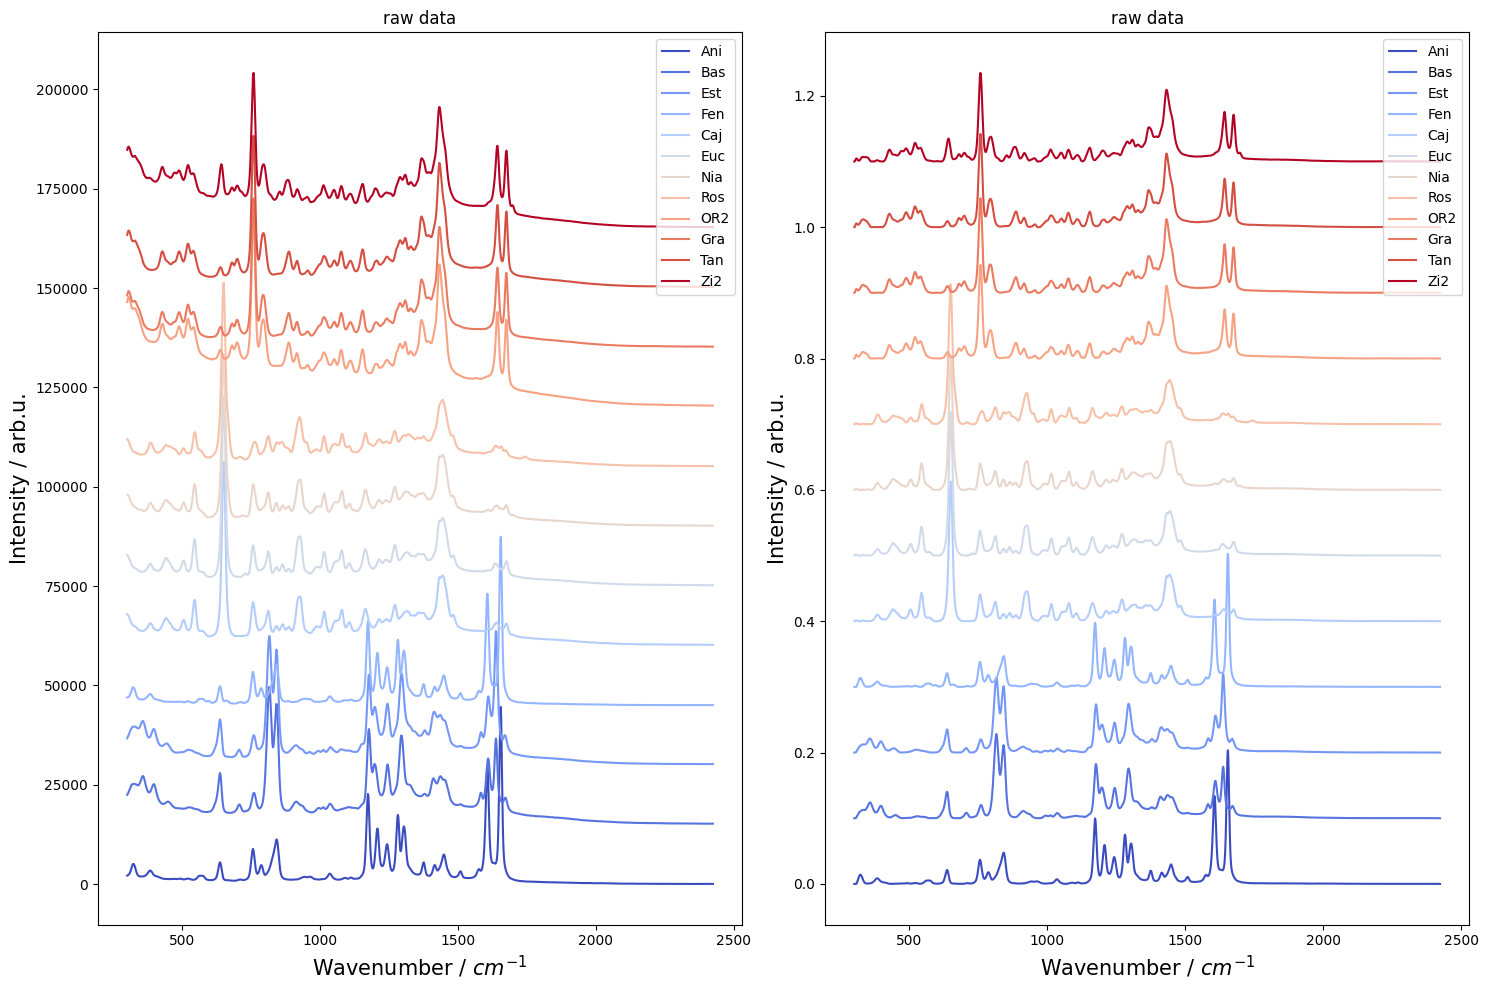

In [15]:
uni_sample = ['Ani', 'Bas', 'Est', 'Fen', 
             'Caj', 'Euc', 'Nia', 'Ros', 
             'OR2', 'Gra', 'Tan', 'Zi2']

colors = mpl.colormaps['coolwarm']
colors = colors(np.linspace(0, 1, len(uni_sample)))

gap_raw = 15000
gap_pre = 0.1

fig, ax = plt.subplots(1, 2, figsize=(15, 10))
for i, s in enumerate(uni_sample):
    ix_plot = (sample_cls == s)
    spec_plot = spec_cls_raw[ix_plot, :]
    spec_mean = np.mean(spec_plot, axis=0)
    ax[0].plot(wn, spec_mean + i*gap_raw, color=colors[i], label=s)
    
ax[0].set_xlabel('Wavenumber / $cm^{-1}$', fontsize=15)
ax[0].set_ylabel('Intensity / arb.u.', fontsize=15)   
ax[0].set_title('raw data')
ax[0].legend(loc = 'upper right')

for i, s in enumerate(uni_sample):
    ix_plot = (sample_cls == s)
    spec_plot = spec_cls[ix_plot, :]
    spec_mean = np.mean(spec_plot, axis=0)
    ax[1].plot(wn_new, spec_mean + i*gap_pre, color=colors[i], label=s)
    
ax[1].set_xlabel('Wavenumber / $cm^{-1}$', fontsize=15)
ax[1].set_ylabel('Intensity / arb.u.', fontsize=15)   
ax[1].set_title('raw data')
ax[1].legend(loc = 'upper right')
plt.tight_layout()
plt.show()

*** INSERT

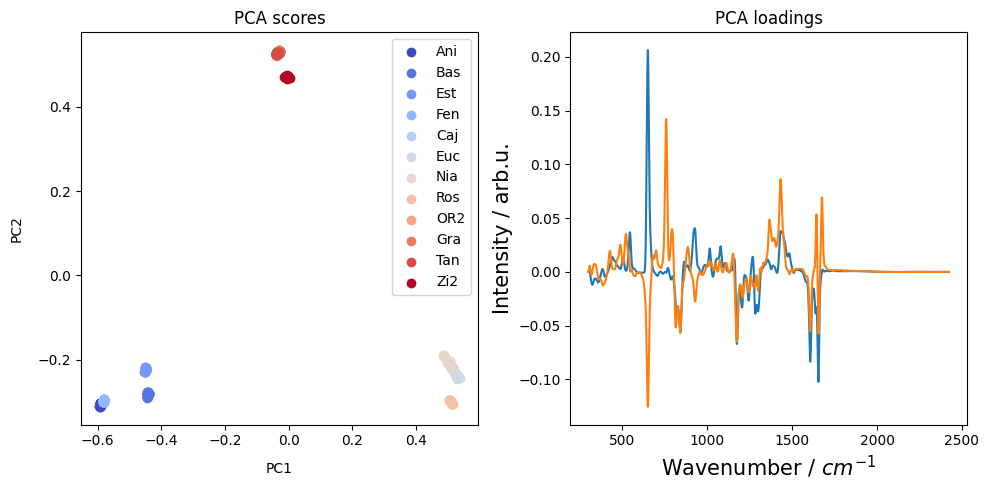

In [16]:
PCA_cls = PCA(n_components=10).fit(spec_cls)
scores_cls = PCA_cls.transform(spec_cls)
loadings_cls = PCA_cls.components_

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

for i, s in enumerate(uni_sample):
    ix_plot = (sample_cls == s)
    ax[0].scatter(scores_cls[ix_plot, 0], scores_cls[ix_plot, 1], color=colors[i], label=s)
    
ax[0].set_xlabel('PC1', labelpad=10)
ax[0].set_ylabel('PC2', labelpad=10)
ax[0].set_title('PCA scores')
ax[0].legend(loc = 'upper right')

ax[1].plot(wn_new, loadings_cls[0, :])
ax[1].plot(wn_new, loadings_cls[1, :])
ax[1].set_xlabel('Wavenumber / $cm^{-1}$', fontsize=15)
ax[1].set_ylabel('Intensity / arb.u.', fontsize=15)   
ax[1].set_title('PCA loadings')

plt.tight_layout()
plt.show()

*** INSERT

In [17]:
from sklearn.cluster import KMeans

n_cluster = 3  
kmeans_pca = KMeans(n_clusters=n_cluster, random_state=0).fit(scores_cls)
cluster_pca = kmeans_pca.labels_
center_pca = []
for i in np.unique(cluster_pca):
    center_pca.append(np.mean(spec_cls[cluster_pca==i, :], axis=0))
    
center_pca = np.vstack(center_pca)

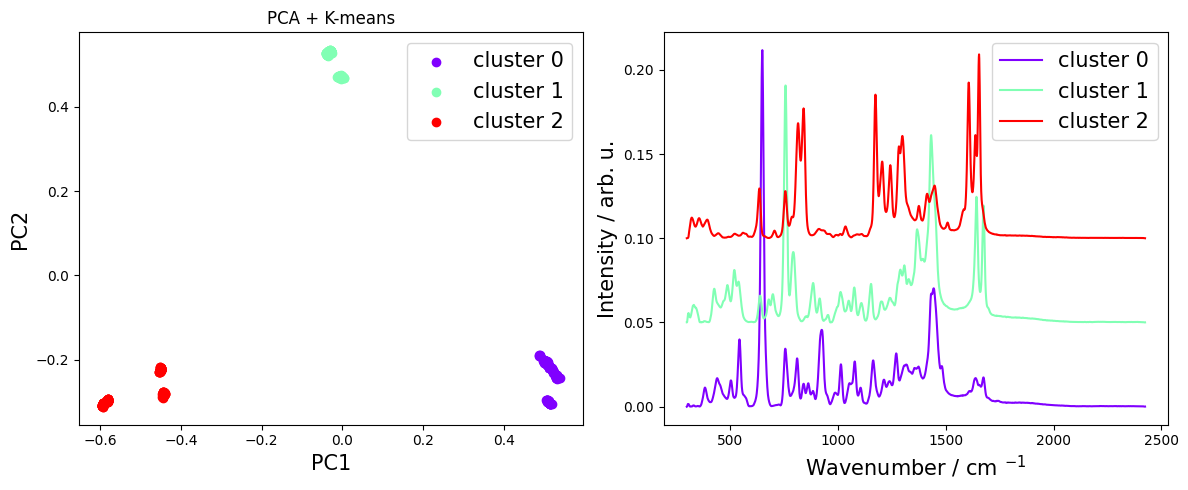

In [18]:
colors = mpl.colormaps['rainbow']
colors = colors(np.linspace(0, 1, n_cluster))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for i in range(n_cluster):
    ax[0].scatter(scores_cls[cluster_pca==i, 0], scores_cls[cluster_pca==i, 1], color=colors[i], label='cluster '+str(i))
ax[0].set_xlabel("PC1", fontsize=15)
ax[0].set_ylabel('PC2', fontsize=15)   
ax[0].legend(fontsize=15)
ax[0].legend(fontsize=15)
ax[0].set_title('PCA + K-means')

gap = 0.05
for i in range(n_cluster):
    ax[1].plot(wn_new, center_pca[i, :] + i*gap, color=colors[i], label='cluster '+str(i))
ax[1].set_xlabel("Wavenumber / cm $^{-1}$", fontsize=15)
ax[1].set_ylabel('Intensity / arb. u.', fontsize=15)   
ax[1].legend(fontsize=15)    

plt.tight_layout()
plt.show()

*** INSERT

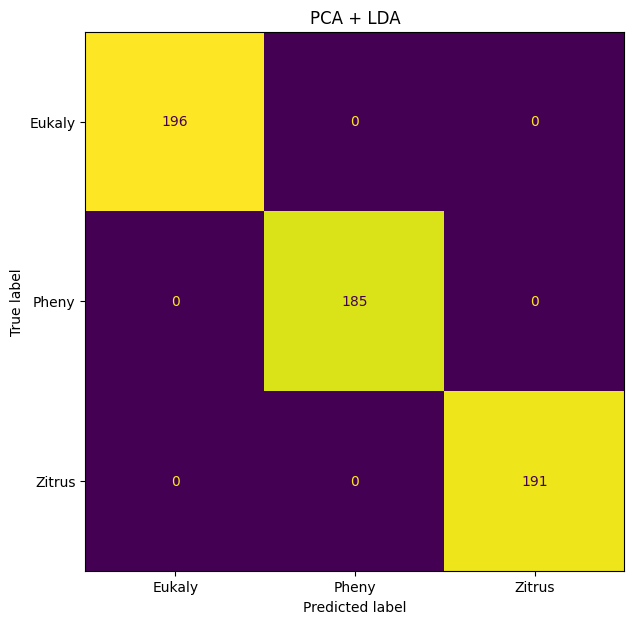

In [19]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

m_cls = LinearDiscriminantAnalysis().fit(scores_cls, sample_type_cls)
pred = m_cls.predict(scores_cls)

cmat_svm = confusion_matrix(sample_type_cls, pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cmat_svm, display_labels=np.unique(sample_type_cls))
    
fig, ax = plt.subplots(1, 1, figsize=(7, 7))
disp.plot(ax=ax, colorbar=False)
plt.title('PCA + LDA')
plt.show()

In [20]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import balanced_accuracy_score

log = LeaveOneGroupOut()     ### leave one replicate our cross-validation
pred = np.zeros_like(sample_type_cls)
accs = []
for i, (train_index, test_index) in enumerate(log.split(spec_cls, sample_type_cls, group_cls)):
    PCA_CV = PCA(n_components=10).fit(spec_cls[train_index, :])
    
    scores_train = PCA_CV.transform(spec_cls[train_index, :])
    scores_test = PCA_CV.transform(spec_cls[test_index, :])

    m_cls = LinearDiscriminantAnalysis().fit(scores_train, sample_type_cls[train_index])
    pred[test_index] = m_cls.predict(scores_test)

    accs = np.append(accs, balanced_accuracy_score(sample_type_cls[test_index], pred[test_index]))    

print(accs)

[1. 1. 1. 1. 1. 1. 1. 1. 1.]


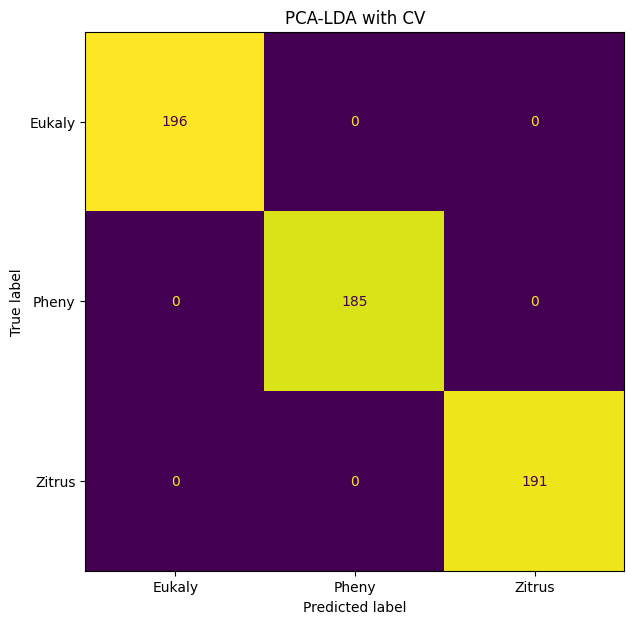

In [21]:
cmat_svm = confusion_matrix(sample_type_cls, pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cmat_svm, display_labels=np.unique(sample_type_cls))
    
fig, ax = plt.subplots(1, 1, figsize=(7, 7))
disp.plot(ax=ax, colorbar=False)
plt.title('PCA-LDA with CV')
plt.show()

*** INSERT

In [22]:
spec_reg_raw     = spec_all[ix_reg, :]
spec_reg         = spec_pre[ix_reg, :]
sample_conc_reg  = sample_type[ix_reg]
group_reg        = groups[ix_reg]

In [23]:
sample_conc_reg = np.array(sample_conc_reg, float)

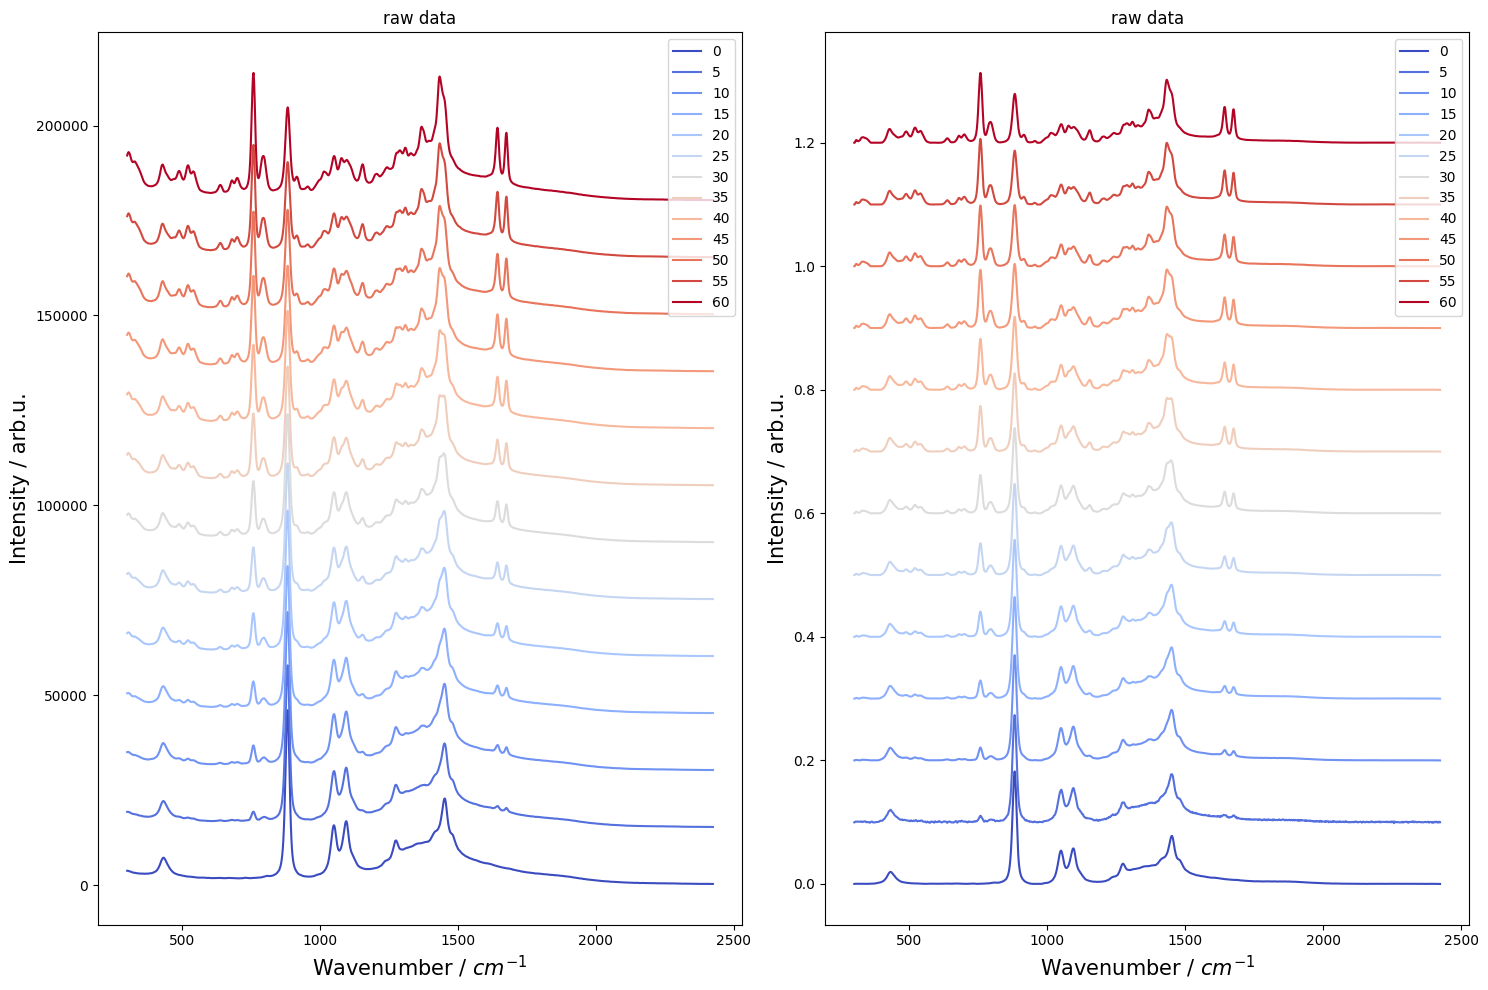

In [24]:
uni_sample = range(0, 65, 5)

colors = mpl.colormaps['coolwarm']
colors = colors(np.linspace(0, 1, len(uni_sample)))

gap_raw = 15000
gap_pre = 0.1

fig, ax = plt.subplots(1, 2, figsize=(15, 10))
for i, s in enumerate(uni_sample):
    ix_plot = (sample_conc_reg == s)
    spec_plot = spec_reg_raw[ix_plot, :]
    spec_mean = np.mean(spec_plot, axis=0)
    ax[0].plot(wn, spec_mean + i*gap_raw, color=colors[i], label=s)
    
ax[0].set_xlabel('Wavenumber / $cm^{-1}$', fontsize=15)
ax[0].set_ylabel('Intensity / arb.u.', fontsize=15)   
ax[0].set_title('raw data')
ax[0].legend(loc = 'upper right')

for i, s in enumerate(uni_sample):
    ix_plot = (sample_conc_reg == s)
    spec_plot = spec_reg[ix_plot, :]
    spec_mean = np.mean(spec_plot, axis=0)
    ax[1].plot(wn_new, spec_mean + i*gap_pre, color=colors[i], label=s)
    
ax[1].set_xlabel('Wavenumber / $cm^{-1}$', fontsize=15)
ax[1].set_ylabel('Intensity / arb.u.', fontsize=15)   
ax[1].set_title('raw data')
ax[1].legend(loc = 'upper right')
plt.tight_layout()
plt.show()

In [25]:
from sklearn.linear_model import LinearRegression

log = LeaveOneGroupOut()     ### leave one replicate our cross-validation
pred = np.zeros_like(sample_conc_reg)
accs = []
for i, (train_index, test_index) in enumerate(log.split(spec_reg, sample_conc_reg, group_reg)):
    PCA_CV = PCA(n_components=10).fit(spec_reg[train_index, :])
    
    scores_train = PCA_CV.transform(spec_reg[train_index, :])
    scores_test = PCA_CV.transform(spec_reg[test_index, :])

    m_cls = LinearRegression().fit(scores_train, sample_conc_reg[train_index])
    pred[test_index] = m_cls.predict(scores_test)  

<Figure size 700x500 with 0 Axes>

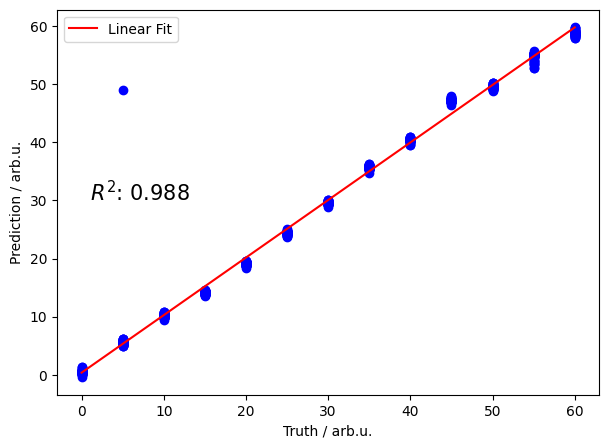

In [27]:
from scipy import stats
fig = plt.figure(figsize=(7, 5))
result = stats.linregress(sample_conc_reg, pred, axis=None)
fit_line = result.slope * sample_conc_reg + result.intercept


fig = plt.figure(figsize=(7, 5))
plt.scatter(sample_conc_reg, pred, color='blue')
plt.plot(sample_conc_reg, fit_line, color="red", label="Linear Fit")
plt.text(1, np.max(fit_line)*0.5, '$R^{2}$: '+str(np.round(result.rvalue**2, 3)), fontsize=15)
plt.xlabel("Truth / arb.u.")
plt.ylabel("Prediction / arb.u.")
plt.legend()
plt.show()